## ⤵️ Imports

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

## ⚠️ Preprocessing

In [3]:
X, y = load_iris(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [4]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 📈 KNN

In [7]:


knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

acc_sem_pca = accuracy_score(y_test, y_pred)
print("Accuracy sem PCA:", acc_sem_pca)

Accuracy sem PCA: 1.0


## 📉 KNN + PCA

In [8]:
pca = PCA(n_components=2)  # reduzindo de 4 → 2
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [9]:
knn_pca = KNeighborsClassifier(n_neighbors=5)
knn_pca.fit(X_train_pca, y_train)

y_pred_pca = knn_pca.predict(X_test_pca)

acc_com_pca = accuracy_score(y_test, y_pred_pca)
print("Accuracy com PCA:", acc_com_pca)

Accuracy com PCA: 0.9333333333333333


## 🗣️ Explicando o PCA

In [10]:
print(pca.explained_variance_ratio_)

[0.72551423 0.23000922]


No PCA, utilizamos apenas 2 compomentes (combinação das features gerando 2 componentes principais):
* PC1 → 72%
* PC2 → 23%
* Total → 95% da informação

**Reduziu de 4 → 2 mantendo quase tudo!**

Com a aplicação do PCA, conseguimos ter mais assertividade nas categorias do dataset.

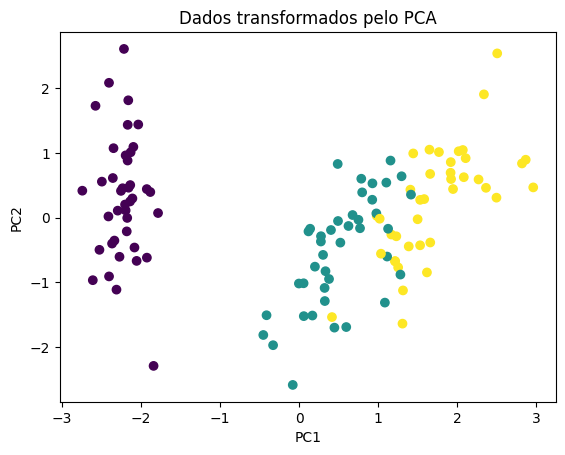

In [12]:
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Dados transformados pelo PCA")
plt.show()

## ✅ Conclusão
* PCA + KNN é uma combinação clássica
* Funciona melhor quando há muitas variáveis
* Troca interpretabilidade por eficiência